# Imputación de *missings*

In [3]:
import pandas as pd
import numpy as np
from scipy.interpolate import interp1d
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("Time-Series.csv", header=0)
df.head()

,Date,value
0,1949-01,114.0
1,1949-02,120.0
2,1949-03,134.0
3,1949-04,67.0
4,1949-05,123.0


In [5]:
df.isna().sum()

Date     0
value    4
dtype: int64

<Axes: >

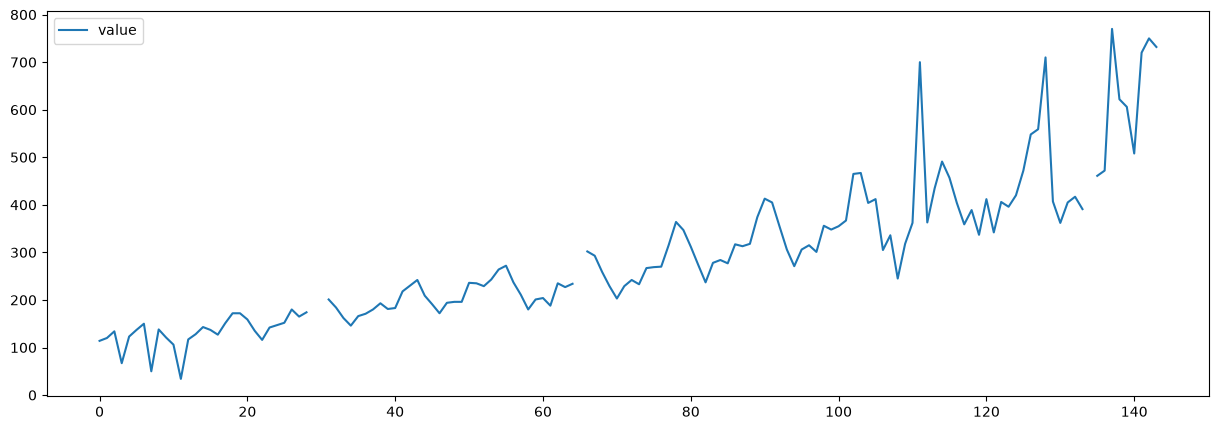

In [6]:
df.plot(figsize=(15,5))

### Preparación de los datos

Antes de aplicar los métodos de imputación, convertimos la columna `Date` a formato datetime y la establecemos como índice, indicando la frecuencia mensual de la serie. Guardamos también las posiciones donde hay valores perdidos, para poder localizarlos y visualizarlos más adelante.

In [7]:
df['Date'] = pd.to_datetime(df['Date'], format='%Y-%m')
df = df.set_index('Date')
df.index.freq = 'MS'

# Posiciones (fechas) donde hay missings
fechas_missing = df.index[df['value'].isna()]
fechas_missing

DatetimeIndex(['1951-06-01', '1951-07-01', '1954-06-01', '1960-03-01'], dtype='datetime64[us]', name='Date', freq=None)

### Interpolación lineal

In [8]:
df_lineal = df.copy()
df_lineal['value'] = df_lineal['value'].interpolate(method='linear')

print(df_lineal.loc[fechas_missing])

            value
Date             
1951-06-01  183.0
1951-07-01  192.0
1954-06-01  268.0
1960-03-01  426.0


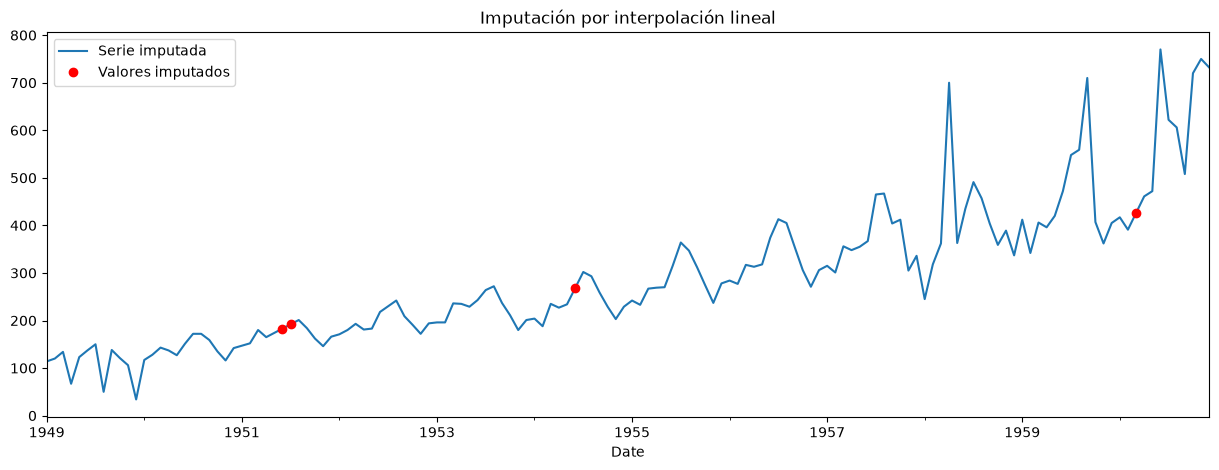

In [9]:
fig, ax = plt.subplots(figsize=(15,5))
df_lineal['value'].plot(ax=ax, label='Serie imputada')
df_lineal.loc[fechas_missing, 'value'].plot(ax=ax, style='ro', label='Valores imputados')
ax.set_title('Imputación por interpolación lineal')
ax.legend()
plt.show()

### Interpolación cúbica

In [10]:
df_cubic = df.copy()
df_cubic['value'] = df_lineal['value'].interpolate(method='cubic')

print(df_lineal.loc[fechas_missing])

            value
Date             
1951-06-01  183.0
1951-07-01  192.0
1954-06-01  268.0
1960-03-01  426.0


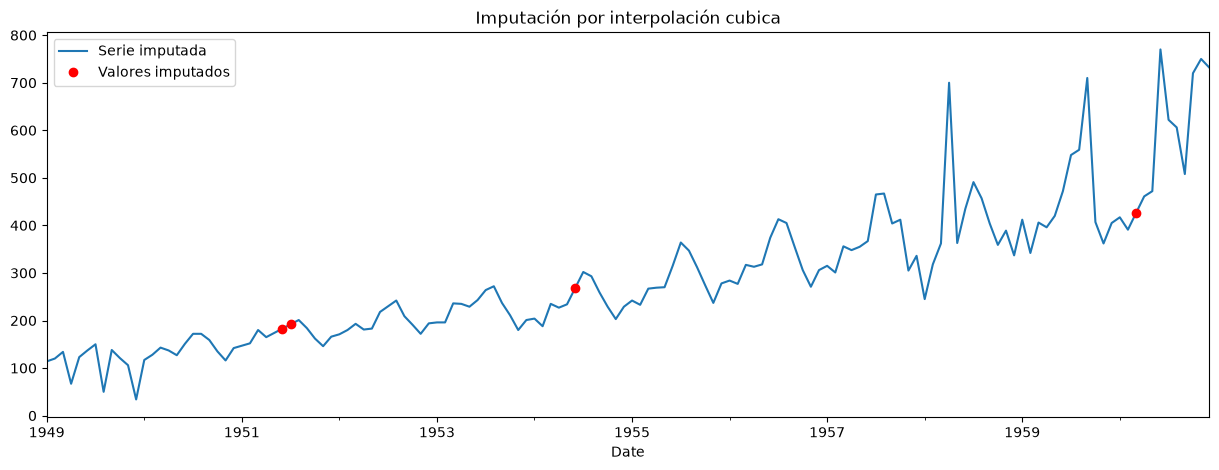

In [11]:
fig, ax = plt.subplots(figsize=(15,5))
df_cubic['value'].plot(ax=ax, label='Serie imputada')
df_cubic.loc[fechas_missing, 'value'].plot(ax=ax, style='ro', label='Valores imputados')
ax.set_title('Imputación por interpolación cubica')
ax.legend()
plt.show()

### Last Observation Carried Forward (LOCF) 

In [12]:
df_locf = df.copy()
df_locf['value'] = df_locf['value'].ffill()

print(df_locf.loc[fechas_missing])

            value
Date             
1951-06-01  174.0
1951-07-01  174.0
1954-06-01  234.0
1960-03-01  391.0


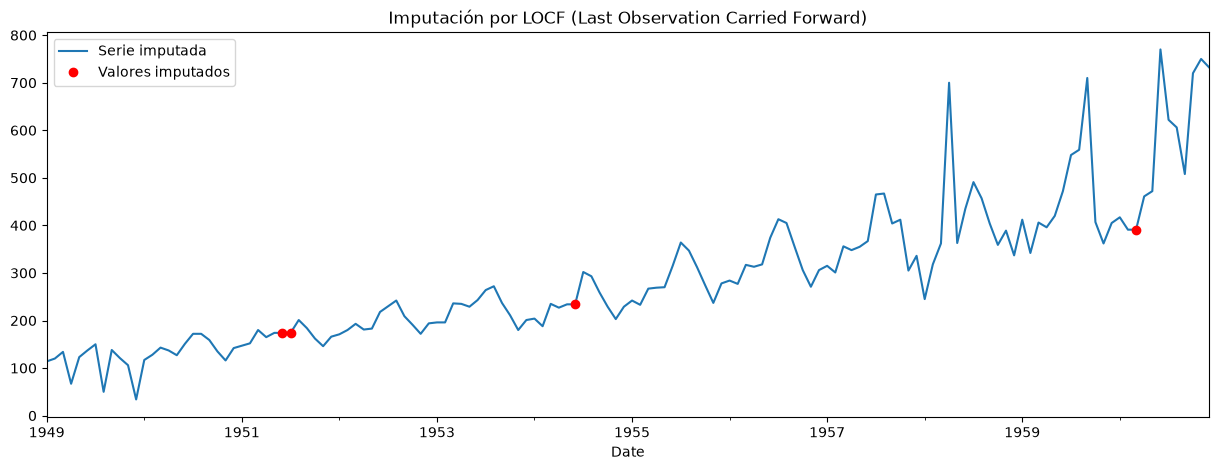

In [13]:
fig, ax = plt.subplots(figsize=(15,5))
df_locf['value'].plot(ax=ax, label='Serie imputada')
df_locf.loc[fechas_missing, 'value'].plot(ax=ax, style='ro', label='Valores imputados')
ax.set_title('Imputación por LOCF (Last Observation Carried Forward)')
ax.legend()
plt.show()

### Next Observation Carried Backward (NOCB)

In [14]:
df_nocb = df.copy()
df_nocb['value'] = df_nocb['value'].bfill()

print(df_nocb.loc[fechas_missing])

            value
Date             
1951-06-01  201.0
1951-07-01  201.0
1954-06-01  302.0
1960-03-01  461.0


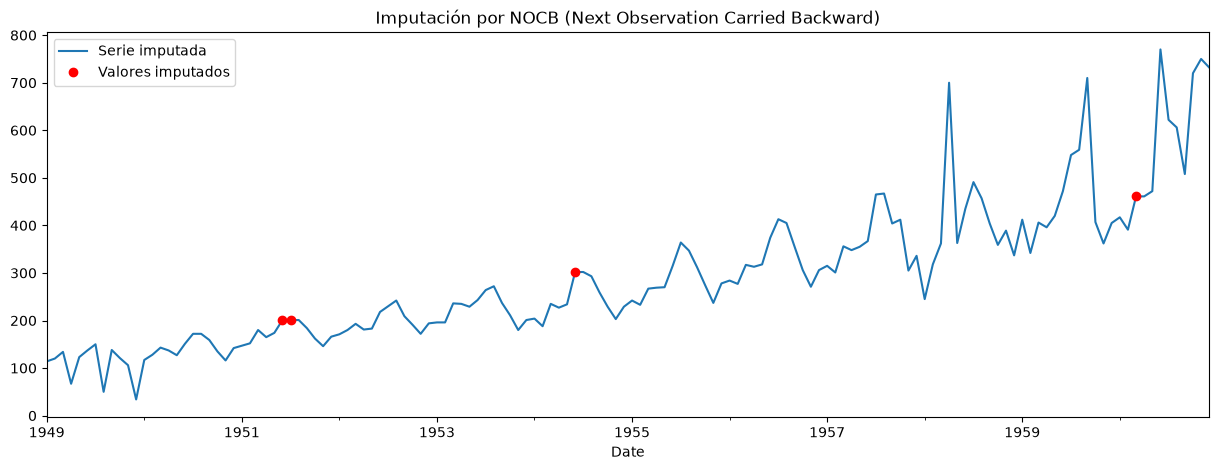

In [15]:
fig, ax = plt.subplots(figsize=(15,5))
df_nocb['value'].plot(ax=ax, label='Serie imputada')
df_nocb.loc[fechas_missing, 'value'].plot(ax=ax, style='ro', label='Valores imputados')
ax.set_title('Imputación por NOCB (Next Observation Carried Backward)')
ax.legend()
plt.show()